# Rank diagram for tscbench_runs

Loads test results with tsml_eval and plots a critical difference diagram of accuracy.

In [1]:
from pathlib import Path

import pandas as pd
from tsml_eval.evaluation.storage import load_classifier_results
from tsml_eval.evaluation.multiple_estimator_evaluation import plot_critical_difference

RUNS = Path("../tscbench_runs")

In [2]:
rows = []
for f in RUNS.glob("*/Predictions/*/testResample*.csv"):
    r = load_classifier_results(str(f))
    rows.append({"model": f.parts[-4], "dataset": f.parts[-2], "resample": r.resample_id,
                 "accuracy": r.accuracy, "log_loss": r.log_loss})
df = pd.DataFrame(rows)

acc = df.groupby(["dataset", "model"])["accuracy"].mean().unstack()
acc

model,Catch22Classifier-1.6.0-eada72,HIVECOTEV2-1.6.0-eada72,MultiRocketHydraClassifier-1.6.0-eada72,TSCGlueEnhancedV4-8c0beca-192df7
dataset,,,,
ACSF1,0.786000,0.862000,0.838000,0.896000
Adiac,0.699233,0.800000,0.824041,0.857289
ArrowHead,0.724571,0.889143,0.890286,0.886857
BME,0.925333,1.000000,1.000000,1.000000
Beef,0.493333,0.800000,0.766667,0.800000
BeetleFly,0.770000,0.900000,0.890000,0.930000
BirdChicken,0.880000,0.950000,0.890000,0.960000
CBF,0.944000,0.998222,0.991111,0.993111
Car,0.756667,0.910000,0.926667,0.910000


In [3]:
n_runs = df.groupby(["dataset", "model"])["resample"].count().unstack().fillna(0).astype(int)
n_runs

model,Catch22Classifier-1.6.0-eada72,HIVECOTEV2-1.6.0-eada72,MultiRocketHydraClassifier-1.6.0-eada72,TSCGlueEnhancedV4-8c0beca-192df7
dataset,,,,
ACSF1,5,5,5,5
Adiac,5,5,5,5
ArrowHead,5,5,5,5
BME,5,5,5,5
Beef,5,5,5,5
BeetleFly,5,5,5,5
BirdChicken,5,5,5,5
CBF,5,5,5,5
Car,5,5,5,5


dropped datasets: ['Crop', 'ElectricDevices', 'FordA', 'FordB', 'HandOutlines', 'InsectWingbeatSound']
datasets used: 54


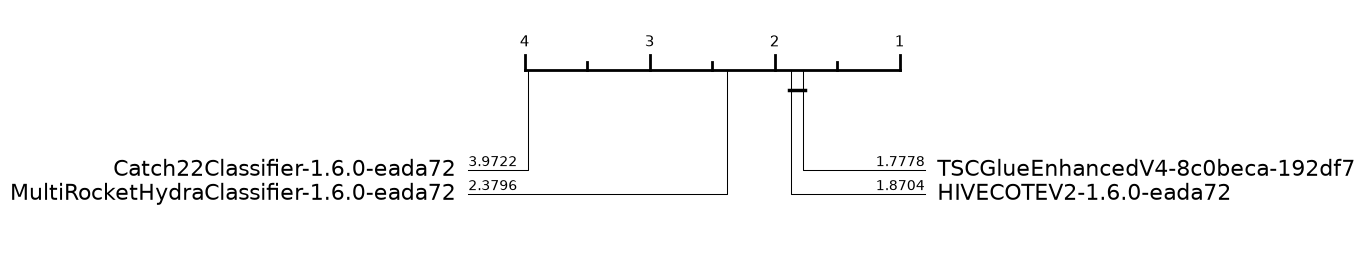

In [4]:
complete = acc.dropna()  # datasets every model has finished
print("dropped datasets:", sorted(set(acc.index) - set(complete.index)))
print("datasets used:", len(complete))

fig, ax = plot_critical_difference(complete.to_numpy(), list(complete.columns))

datasets used: 54


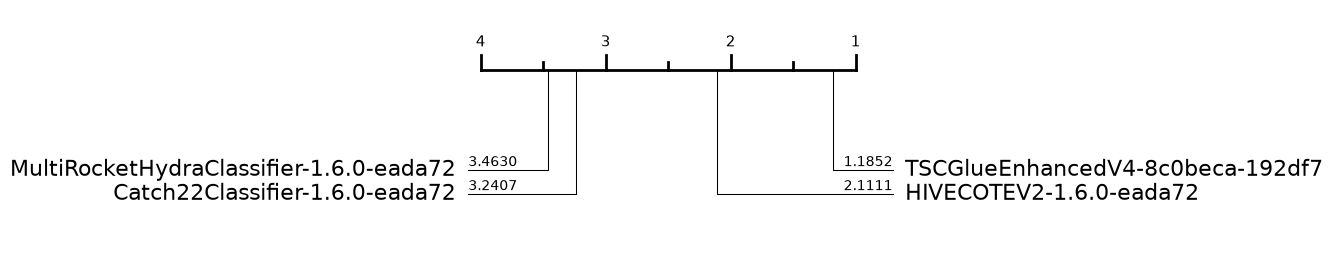

In [5]:
ll = df.groupby(["dataset", "model"])["log_loss"].mean().unstack().dropna()
print("datasets used:", len(ll))

fig, ax = plot_critical_difference(ll.to_numpy(), list(ll.columns), lower_better=True)